# 02 · Segmentação comportamental (PCA + K-means)

**Pergunta do notebook:** que tipos de cliente existem, olhando só **como eles usam e pagam o cartão**?

Esses grupos (segmentos) dão o contexto que atravessa o projeto: o dashboard, a política por faixa e a checagem de desempenho por grupo.

**Regras deste notebook**
- **Sem o alvo** para formar os grupos: a segmentação descreve comportamento, ela não prevê default. A taxa de default de cada grupo só é olhada **depois**, como descrição.
- **Sem perfil demográfico** (sexo, idade, escolaridade, estado civil): grupos devem refletir comportamento, não quem a pessoa é.
- **Só o treino** (24.000 clientes).

**Critérios fixados antes de rodar**

| Decisão | Critério |
|---|---|
| Nº de componentes do PCA | o menor que explique **≥ 80%** da variância |
| Nº de grupos (Parte B) | k entre 3 e 8, melhor silhueta, com todo grupo ≥ 5% dos clientes |
| Estabilidade (Parte B) | ARI ≥ 0,8 entre sementes diferentes |
| Grupo como variável do modelo (Parte B) | só se o PR AUC subir com win rate > 60% nos folds |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from credit_risk import config
from credit_risk.features import behavior_features
from credit_risk.segmentation import (
    choose_n_components,
    explained_variance_table,
    loadings,
    make_pca_pipeline,
)
from credit_risk.split import load_train
from credit_risk.viz import CONTEXT, HIGHLIGHT, SURFACE, pct, save, set_style

set_style()
pd.set_option("display.precision", 3)

df = load_train()
X = behavior_features(df)
X.shape

(24000, 17)

## 1. As features comportamentais

Para cada cliente, três comportamentos ao longo dos meses:

| Feature | O que mede | Regra fixa |
|---|---|---|
| `utilization_1..6` | quanto do limite a fatura ocupa (fatura ÷ limite) | fatura negativa → 0; limitado a 150% |
| `payment_ratio_1..5` | quanto da fatura anterior o cliente pagou | sem fatura a pagar → 1 (em dia); pagar a mais → 1 |
| `delay_1..6` | meses de atraso | status ≤ 0 → 0 |

O índice 1 é setembro (o mais recente). A taxa de pagamento tem só 5 meses porque o pagamento de abril quitaria a fatura de março, que não está nos dados.

São **regras fixas**, iguais para qualquer cliente, por isso não há vazamento de dados.

In [2]:
X.describe().T[["mean", "50%", "min", "max"]]

,mean,50%,min,max
utilization_1,0.421,0.315,0.0,1.5
utilization_2,0.409,0.296,0.0,1.5
utilization_3,0.390,0.272,0.0,1.5
utilization_4,0.358,0.242,0.0,1.5
utilization_5,0.332,0.211,0.0,1.5
utilization_6,0.317,0.182,0.0,1.5
payment_ratio_1,0.403,0.101,0.0,1.0
payment_ratio_2,0.412,0.104,0.0,1.0
payment_ratio_3,0.403,0.084,0.0,1.0
payment_ratio_4,0.404,0.078,0.0,1.0


## 2. Por que padronizar antes do PCA

O PCA procura as direções de **maior variação**. Se uma coluna varia de 0 a 8 (atraso) e outra de 0 a 1 (taxa de pagamento), o atraso "grita mais alto" só por causa da escala, e não por ser mais importante.

A **padronização** (*standardization*) põe todas as colunas na mesma régua: subtrai a média e divide pelo desvio-padrão. Exemplo: se a utilização média é 0,40 com desvio de 0,30, um cliente com 0,70 vira (0,70 − 0,40) ÷ 0,30 = **+1,0** ("um desvio acima da média").

A média e o desvio são **aprendidos dos dados**, por isso ficam dentro do pipeline: na validação cruzada, eles são recalculados só com o treino de cada fold.

In [3]:
spread = X.std().groupby(lambda c: c.rsplit("_", 1)[0]).mean()
spread.rename("desvio-padrão médio (antes de padronizar)").to_frame()

,desvio-padrão médio (antes de padronizar)
delay,0.753
payment_ratio,0.447
utilization,0.371


## 3. PCA: quantas "direções" resumem o comportamento?

O PCA (*análise de componentes principais*) troca as 17 colunas por novas colunas, os **componentes**, que são combinações das originais. O primeiro componente guarda a maior variação possível; o segundo, a maior variação que sobrou, sem repetir a informação do primeiro; e assim por diante.

**Álgebra linear por trás:** os componentes são os **autovetores** da matriz de covariância dos dados padronizados, e o **autovalor** de cada um diz quanta variância ele carrega. Como cada coluna padronizada tem variância 1, a soma dos autovalores é 17.

In [4]:
pipe = make_pca_pipeline().fit(df)
pca_full = pipe.named_steps["pca"]
variance = explained_variance_table(pca_full)
n_comp = choose_n_components(variance["acumulada"])
kaiser = int((variance["autovalor"] > 1).sum())
print(f"Soma dos autovalores: {variance['autovalor'].sum():.2f} (= nº de colunas)")
print(f"Componentes para >= 80%: {n_comp}  |  Regra de Kaiser (autovalor > 1): {kaiser}")
variance.head(8)

Soma dos autovalores: 17.00 (= nº de colunas)
Componentes para >= 80%: 4  |  Regra de Kaiser (autovalor > 1): 3


,variancia,acumulada,autovalor
PC1,0.507,0.507,8.614
PC2,0.195,0.702,3.320
PC3,0.067,0.769,1.137
PC4,0.054,0.823,0.921
PC5,0.035,0.858,0.601
PC6,0.029,0.887,0.494
PC7,0.022,0.909,0.373
PC8,0.017,0.927,0.295


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/seg_01_variancia_pca.png')

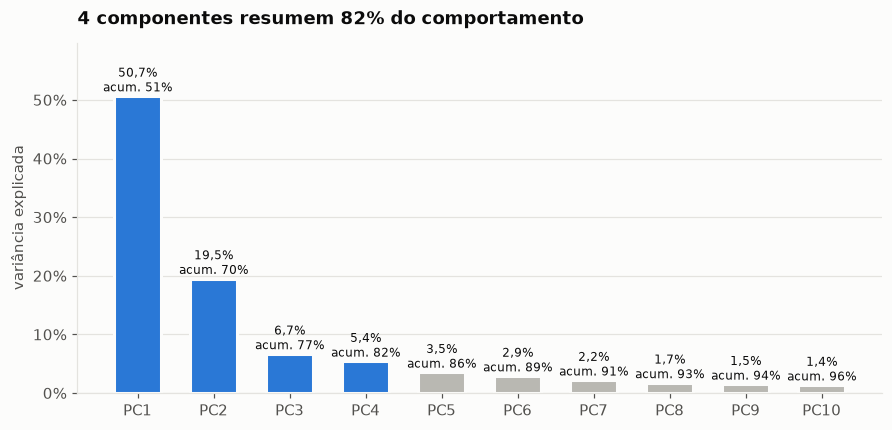

In [5]:
top = variance.head(10)
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [HIGHLIGHT if i < n_comp else CONTEXT for i in range(len(top))]
ax.bar(top.index, top["variancia"], color=colors, width=0.62, edgecolor=SURFACE, linewidth=2)
for i, (v, acc) in enumerate(zip(top["variancia"], top["acumulada"], strict=True)):
    ax.annotate(
        f"{pct(v)}\nacum. {pct(acc, 0)}",
        (i, v),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, 0)))
ax.set_ylabel("variância explicada")
ax.margins(y=0.18)
kept = pct(top["acumulada"].iloc[n_comp - 1], 0)
ax.set_title(f"{n_comp} componentes resumem {kept} do comportamento")
save(fig, "seg_01_variancia_pca")

**Evidência:** o 1º componente sozinho explica **50,7%** da variação; os 4 primeiros, **82,3%**. A regra de Kaiser indicaria 3 (o 4º tem autovalor 0,92, um pouco abaixo de 1).

**Decisão:** fico com **4 componentes**, como fixado antes de rodar. Trocar 17 colunas por 4 perde menos de 18% da informação e deixa o K-means mais estável.

## 4. O que cada componente significa

As **cargas** (*loadings*) dizem quanto cada coluna original pesa em cada componente. Carga positiva: quando a coluna sobe, o componente sobe. Carga negativa: o contrário. Carga perto de zero: a coluna quase não participa.

,PC1,PC2,PC3,PC4
utilization_1,0.28,-0.16,0.23,0.00
utilization_2,0.30,-0.15,0.23,-0.02
utilization_3,0.30,-0.14,0.23,-0.08
utilization_4,0.30,-0.11,0.23,-0.16
utilization_5,0.30,-0.08,0.22,-0.22
utilization_6,0.29,-0.07,0.21,-0.23
payment_ratio_1,-0.28,0.06,0.24,-0.27
payment_ratio_2,-0.29,0.06,0.29,-0.22
payment_ratio_3,-0.28,0.06,0.34,-0.15
payment_ratio_4,-0.27,0.05,0.35,-0.09


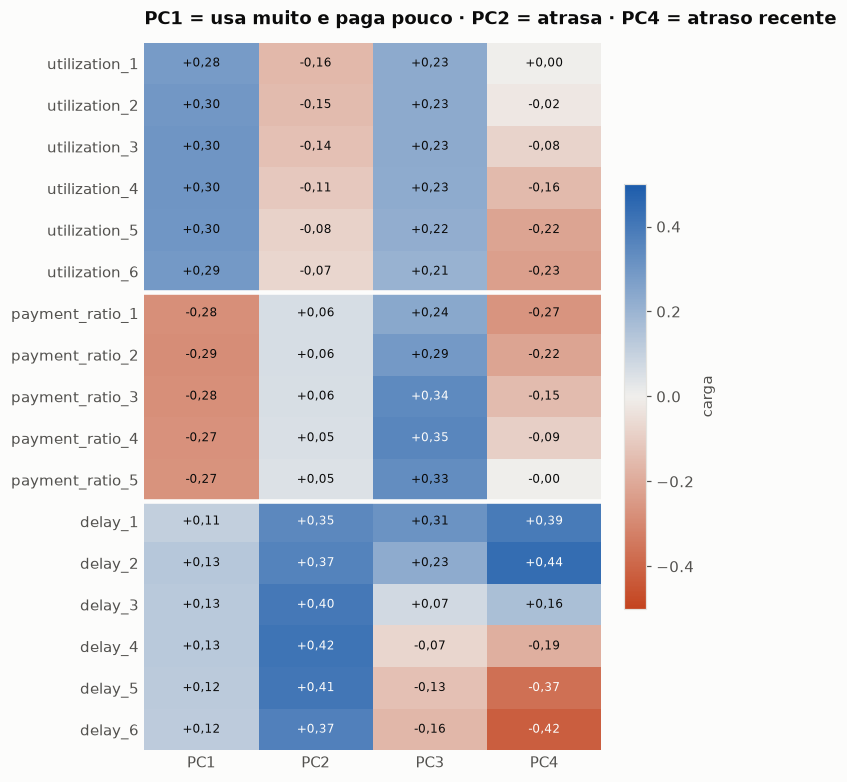

In [6]:
pca = make_pca_pipeline(n_comp).fit(df).named_steps["pca"]
load = loadings(pca, config.BEHAVIOR_FEATURES)

diverging = LinearSegmentedColormap.from_list("div", ["#c4441f", "#f0efec", "#1c5cab"])
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(load.to_numpy(), cmap=diverging, vmin=-0.5, vmax=0.5, aspect="auto")
for (i, j), v in np.ndenumerate(load.to_numpy()):
    ax.text(
        j,
        i,
        f"{v:+.2f}".replace(".", ","),
        ha="center",
        va="center",
        fontsize=8,
        color=SURFACE if abs(v) > 0.33 else "#0b0b0b",
    )
ax.set_xticks(range(n_comp), load.columns)
ax.set_yticks(range(len(load)), load.index)
for y in (5.5, 10.5):
    ax.axhline(y, color=SURFACE, linewidth=3)
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="carga")
ax.set_title("PC1 = usa muito e paga pouco · PC2 = atrasa · PC4 = atraso recente")
save(fig, "seg_02_cargas_pca")
load.round(2)

**Leitura das cargas:**

| Componente | Variância | Cargas fortes | Nome de negócio |
|---|---|---|---|
| **PC1** | 50,7% | utilização **+** (≈ 0,30) e taxa de pagamento **−** (≈ −0,28) em todos os meses | **"rotativo"**: usa muito do limite e paga pouco da fatura. No polo oposto, quem usa pouco e quita tudo |
| **PC2** | 19,5% | atraso **+** em todos os meses (0,35 a 0,42) | **"atraso"**: quanto o cliente atrasa, de forma geral |
| **PC3** | 6,7% | utilização **+** e taxa de pagamento **+** juntas; atraso recente + e antigo − | **"usa muito, mas paga"**: grande utilização sem rotativo. Leitura menos limpa que as anteriores |
| **PC4** | 5,4% | atraso **recente +** (set/ago: 0,39 e 0,44) e **antigo −** (mai/abr: −0,37 e −0,42) | **"tendência do atraso"**: positivo = **piorando** (o atraso começou agora); negativo = melhorando |

A EDA já tinha mostrado que o atraso recente vale mais que o antigo. O PC4 isola exatamente essa diferença, e ele **não depende do alvo**: o PCA chegou lá só olhando o comportamento.

**Os sinais de um componente são arbitrários:** o PCA poderia ter devolvido o PC1 com todas as cargas invertidas, e a leitura seria a mesma ("paga muito e usa pouco"). O que importa é o contraste entre as colunas.

## 5. Os clientes no mapa dos dois primeiros componentes

Cada ponto é um cliente, posicionado pelos seus valores em PC1 (rotativo) e PC2 (atraso). As áreas mais escuras concentram mais clientes.

PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/seg_03_mapa_pca.png')

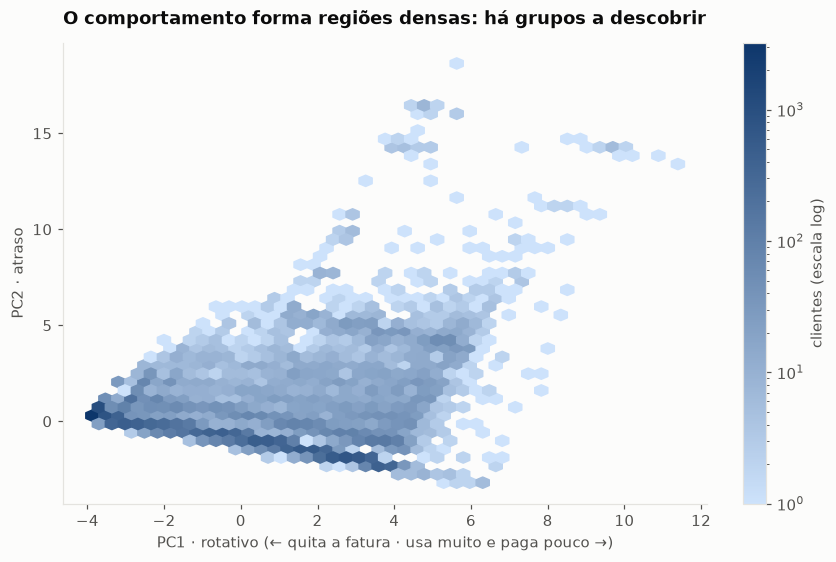

In [7]:
scores = pd.DataFrame(make_pca_pipeline(n_comp).fit_transform(df), columns=load.columns)
fig, ax = plt.subplots(figsize=(7.5, 5))
hb = ax.hexbin(
    scores["PC1"],
    scores["PC2"],
    gridsize=45,
    bins="log",
    mincnt=1,
    cmap=LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#0d366b"]),
)
ax.grid(False)
fig.colorbar(hb, ax=ax, label="clientes (escala log)")
ax.set_xlabel("PC1 · rotativo (← quita a fatura · usa muito e paga pouco →)")
ax.set_ylabel("PC2 · atraso")
ax.set_title("O comportamento forma regiões densas: há grupos a descobrir")
save(fig, "seg_03_mapa_pca")

**Evidência:** os clientes não se espalham de forma uniforme. Há uma grande massa com pouco atraso, que vai de "quita tudo" (esquerda) a "rotativo" (direita), e "braços" que sobem na direção do atraso.

**Decisão:** seguir para o K-means (Parte B) usando os **4 componentes**, para encontrar e nomear esses grupos.